# Bifurcations in First-Order Differential Equations

How the long-term behaviour of $\dfrac{dy}{dt} = f(y, r)$ changes, sometimes suddenly, as a parameter $r$ is varied.

**Contents**
1. Autonomous equations, equilibria and the phase line
2. Stability of equilibria
3. What is a bifurcation?
4. Saddle-node bifurcation
5. Transcritical bifurcation
6. Pitchfork bifurcations (supercritical and subcritical)
7. Hysteresis
8. Application: fish harvesting and sudden collapse
9. Computing bifurcation diagrams numerically
10. Summary
11. Exercises

*Prerequisite:* the notes in `first-order-differential-equations.ipynb`, especially direction fields and RK4.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (7, 4.5)
plt.rcParams["axes.grid"] = True


def rk4(f, t0, y0, h, n):
    # RK4 for y' = f(t, y). y0 may be a NumPy array to integrate many initial conditions at once.
    t = t0 + h * np.arange(n + 1)
    y = np.zeros((n + 1,) + np.shape(y0))
    y[0] = y0
    for i in range(n):
        k1 = f(t[i], y[i])
        k2 = f(t[i] + h / 2, y[i] + h / 2 * k1)
        k3 = f(t[i] + h / 2, y[i] + h / 2 * k2)
        k4 = f(t[i] + h, y[i] + h * k3)
        y[i + 1] = y[i] + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
    return t, y

## 1. Autonomous equations and the phase line

An equation is **autonomous** if the right-hand side does not depend explicitly on $t$:

$$\frac{dy}{dt} = f(y).$$

Its slope depends only on the current value of $y$, so we can understand *every* solution without solving the equation, just by looking at the sign of $f$.

* **Equilibria (fixed points):** values $y^*$ with $f(y^*) = 0$. The constant function $y(t) = y^*$ is a solution.
* Where $f(y) > 0$, $y$ increases; where $f(y) < 0$, $y$ decreases.
* A solution can never cross an equilibrium (by uniqueness), so it moves monotonically towards an equilibrium or off to $\pm\infty$.

The **phase line** summarises this: a $y$-axis marked with the equilibria and arrows showing the direction of motion between them.

### Worked example 1.1

$y' = y(1 - y)(y - 3)$.

1. Equilibria: $y^* = 0,\ 1,\ 3$.
2. Sign of $f$ on each interval (test points):

| interval | test $y$ | $f(y)$ | direction |
|---|---|---|---|
| $y < 0$ | $-1$ | $(-1)(2)(-4) = 8 > 0$ | ↑ towards 0 |
| $0 < y < 1$ | $0.5$ | $(0.5)(0.5)(-2.5) = -0.625 < 0$ | ↓ towards 0 |
| $1 < y < 3$ | $2$ | $(2)(-1)(-1) = 2 > 0$ | ↑ towards 3 |
| $y > 3$ | $4$ | $(4)(-3)(1) = -12 < 0$ | ↓ towards 3 |

3. Conclusion: $y^* = 0$ and $y^* = 3$ attract nearby solutions (**stable**); $y^* = 1$ repels them (**unstable**).

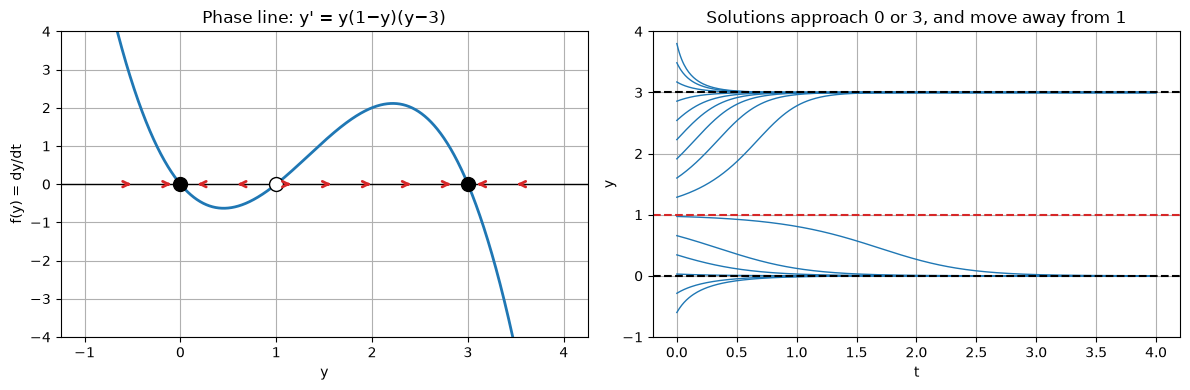

In [2]:
def phase_line(f, ylim, ax=None, title=""):
    # Plot f(y) against y, mark equilibria and flow arrows.
    # Filled = stable, open = unstable, half-filled = semi-stable.
    ax = ax or plt.gca()
    y = np.linspace(*ylim, 2001)
    fy = f(y)
    ax.plot(y, fy, "C0", lw=2)
    ax.axhline(0, color="k", lw=1)
    # equilibria: grid points where |f| has a local minimum within one grid step of zero
    a = np.abs(fy)
    for i in range(3, len(y) - 3):
        step = max(abs(fy[i - 1] - fy[i]), abs(fy[i + 1] - fy[i]))
        if a[i] <= a[i - 1] and a[i] < a[i + 1] and a[i] <= step:
            left, right = fy[i - 3], fy[i + 3]
            if left > 0 > right:
                style = dict(mfc="k")
            elif left < 0 < right:
                style = dict(mfc="white")
            else:
                style = dict(mfc="k", fillstyle="left" if left > 0 else "right", mfcalt="white")
            ax.plot(y[i], 0, "o", ms=10, mec="k", zorder=3, **style)
    # arrows along the axis
    for ya in np.linspace(*ylim, 13)[1:-1]:
        s = np.sign(f(ya))
        if s:
            ax.annotate("", (ya + 0.12 * s * (ylim[1] - ylim[0]) / 6, 0), (ya, 0),
                        arrowprops=dict(arrowstyle="->", color="C3", lw=2))
    ax.set_xlabel("y"); ax.set_ylabel("f(y) = dy/dt"); ax.set_title(title)
    return ax


f = lambda y: y * (1 - y) * (y - 3)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
phase_line(f, (-1, 4), ax=axes[0], title="Phase line: y' = y(1−y)(y−3)")
axes[0].set_ylim(-4, 4)

t, Y = rk4(lambda t, y: f(y), 0, np.linspace(-0.6, 3.8, 15), 0.01, 400)
axes[1].plot(t, Y, "C0", lw=1)
for ys, c in [(0, "k"), (1, "C3"), (3, "k")]:
    axes[1].axhline(ys, color=c, ls="--")
axes[1].set_ylim(-1, 4); axes[1].set_xlabel("t"); axes[1].set_ylabel("y")
axes[1].set_title("Solutions approach 0 or 3, and move away from 1")
plt.tight_layout()

## 2. Stability of equilibria

**Linear stability test.** Near an equilibrium, write $y = y^* + \eta$ with $\eta$ small. A Taylor expansion gives

$$\eta' = f(y^* + \eta) \approx f(y^*) + f'(y^*)\,\eta = f'(y^*)\,\eta \quad\Longrightarrow\quad \eta(t) \approx \eta_0\, e^{f'(y^*)\,t}.$$

| $f'(y^*)$ | small perturbations | equilibrium is |
|---|---|---|
| $< 0$ | decay | **stable** (attracting) |
| $> 0$ | grow | **unstable** (repelling) |
| $= 0$ | test is inconclusive | look at higher-order terms or the phase line |

The value $1/|f'(y^*)|$ is the **characteristic time** of the approach to, or departure from, $y^*$.

### Worked example 2.1

For $f(y) = y(1-y)(y-3) = -y^3 + 4y^2 - 3y$, we have $f'(y) = -3y^2 + 8y - 3$:

* $f'(0) = -3 < 0$: stable, characteristic time $1/3$
* $f'(1) = -3 + 8 - 3 = 2 > 0$: unstable
* $f'(3) = -27 + 24 - 3 = -6 < 0$: stable, characteristic time $1/6$

This agrees with the phase line.

### Worked example 2.2: when the test fails

$y' = y^2$ has $y^* = 0$ with $f'(0) = 0$. Since $y^2 \ge 0$, solutions below 0 move up towards 0, and solutions above 0 move up, away from it. The equilibrium is **semi-stable**: attracting from one side, repelling from the other. As we will see, this is exactly what an equilibrium looks like *at* a bifurcation.

In [3]:
fp = lambda y: -3 * y**2 + 8 * y - 3
for ys in [0, 1, 3]:
    print(f"y* = {ys}:  f'(y*) = {fp(ys):+d}  ->  {'stable' if fp(ys) < 0 else 'unstable'}")

# Check the exponential rate numerically: start near y* = 3 and fit the decay rate
t, Y = rk4(lambda t, y: f(y), 0, 3.01, 0.01, 200)
rate = np.polyfit(t[:100], np.log(np.abs(Y[:100] - 3)), 1)[0]
print(f"\nmeasured decay rate of |y - 3| ≈ {rate:.3f}   (theory f'(3) = -6)")

y* = 0:  f'(y*) = -3  ->  stable
y* = 1:  f'(y*) = +2  ->  unstable
y* = 3:  f'(y*) = -6  ->  stable

measured decay rate of |y - 3| ≈ -6.006   (theory f'(3) = -6)


## 3. What is a bifurcation?

Now let the equation depend on a parameter $r$:

$$\frac{dy}{dt} = f(y, r).$$

As $r$ changes, the graph of $f$ shifts and deforms. Usually the equilibria just move a little and keep their stability. A **bifurcation** occurs at a value $r = r_c$ where the *qualitative* picture changes: equilibria are created or destroyed, or their stability changes.

**Necessary conditions at a bifurcation point $(y^*, r_c)$:**

$$f(y^*, r_c) = 0 \qquad\text{and}\qquad \frac{\partial f}{\partial y}(y^*, r_c) = 0.$$

The first says $y^*$ is an equilibrium. The second says the linear stability test is inconclusive there: the equilibrium is about to change stability, or two equilibria are merging.

A **bifurcation diagram** plots the equilibria $y^*$ against $r$, conventionally with **solid lines for stable** and **dashed lines for unstable** branches.

Every one-dimensional bifurcation looks, near the bifurcation point, like one of a few **normal forms**:

| Type | Normal form | What happens at $r = 0$ |
|---|---|---|
| Saddle-node | $y' = r + y^2$ | two equilibria collide and disappear |
| Transcritical | $y' = ry - y^2$ | two equilibria exchange stability |
| Supercritical pitchfork | $y' = ry - y^3$ | one stable equilibrium splits into two |
| Subcritical pitchfork | $y' = ry + y^3$ | two unstable equilibria merge into a stable one, which then becomes unstable |

In [4]:
def branch(ax, r, y, stable, **kw):
    ax.plot(r, y, "k-" if stable else "k--", lw=2.5 if stable else 1.8, **kw)

def phase_lines_row(f, rs, ylim, suptitle):
    fig, axes = plt.subplots(1, len(rs), figsize=(4 * len(rs), 3.2), sharey=True)
    for ax, r in zip(axes, rs):
        phase_line(lambda y: f(y, r), ylim, ax=ax, title=f"r = {r}")
        ax.set_ylim(-2, 2)
    fig.suptitle(suptitle, y=1.03)
    plt.tight_layout()

## 4. Saddle-node bifurcation

**Normal form:** $\quad y' = r + y^2.$

* **Equilibria:** $y^2 = -r$, so $y^* = \pm\sqrt{-r}$. They exist only when $r \le 0$.
* **Stability:** $f'(y) = 2y$.
  * $y^* = -\sqrt{-r}$: $f' = -2\sqrt{-r} < 0$, **stable**
  * $y^* = +\sqrt{-r}$: $f' = +2\sqrt{-r} > 0$, **unstable**
* **Bifurcation conditions:** $f = r + y^2 = 0$ and $f_y = 2y = 0$ give $(y^*, r_c) = (0, 0)$.

| $r$ | equilibria | picture |
|---|---|---|
| $r < 0$ | two: one stable, one unstable | a stable state exists |
| $r = 0$ | one, semi-stable ($y^* = 0$) | the two have merged |
| $r > 0$ | none | every solution escapes to $+\infty$ |

### Worked example 4.1

For $r = -4$: equilibria $y^* = \pm 2$; $f'(-2) = -4$ (stable), $f'(2) = 4$ (unstable). A solution starting at $y_0 = 1$ lies between them, where $f(1) = -4 + 1 = -3 < 0$, so it decreases towards $-2$.

### The "ghost" and the bottleneck

Just past the bifurcation ($r$ small and positive) there is no equilibrium, but $f$ is still tiny near $y = 0$, so solutions **slow down dramatically** there before escaping. The time to pass through is

$$T = \int_{-\infty}^{\infty} \frac{dy}{r + y^2} = \frac{\pi}{\sqrt{r}},$$

which becomes very long as $r \to 0^{+}$. This **bottleneck** is an early-warning sign that a system is near a saddle-node.

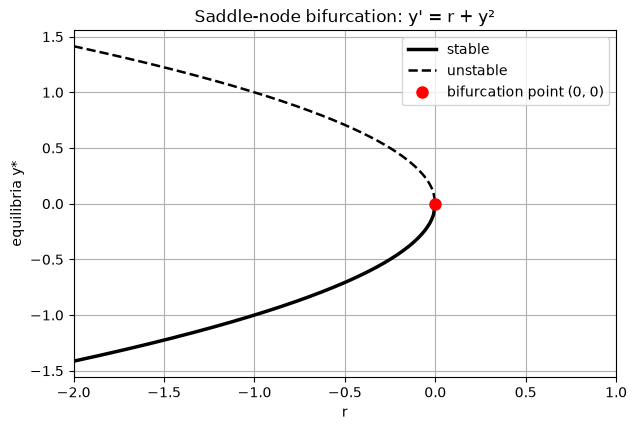

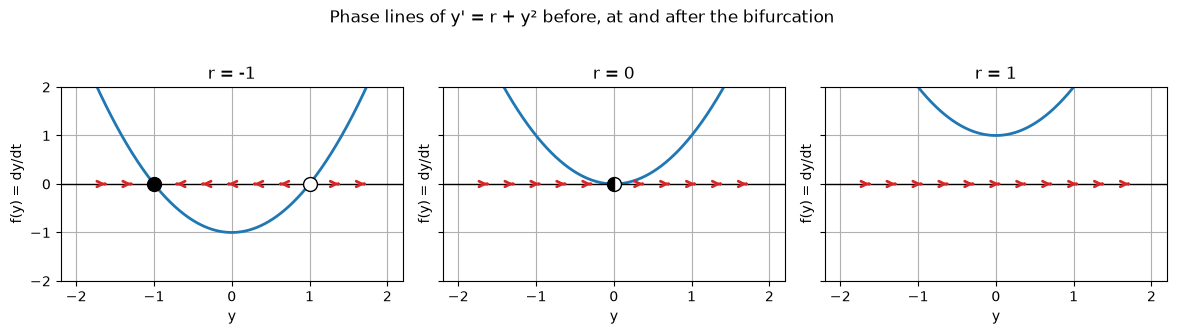

In [5]:
fig, ax = plt.subplots()
r = np.linspace(-2, 0, 200)
branch(ax, r, -np.sqrt(-r), True, label="stable")
branch(ax, r, np.sqrt(-r), False, label="unstable")
ax.plot(0, 0, "ro", ms=8, label="bifurcation point (0, 0)")
ax.set_xlim(-2, 1); ax.set_xlabel("r"); ax.set_ylabel("equilibria y*")
ax.set_title("Saddle-node bifurcation: y' = r + y²"); ax.legend();

phase_lines_row(lambda y, r: r + y**2, [-1, 0, 1], (-2, 2), "Phase lines of y' = r + y² before, at and after the bifurcation")

In [6]:
# Bottleneck: time to travel from y = -10 to y = +10 for small r > 0
def passage_time(r, h=1e-3):
    y, t = -10.0, 0.0
    g = lambda t, y: r + y**2
    while y < 10:
        k1 = g(t, y); k2 = g(t, y + h/2*k1); k3 = g(t, y + h/2*k2); k4 = g(t, y + h*k3)
        y += h / 6 * (k1 + 2*k2 + 2*k3 + k4); t += h
    return t

print(f"{'r':>7} {'RK4 time':>10} {'(2/√r)·arctan(10/√r)':>22} {'π/√r':>8}")
for r in [1.0, 0.1, 0.01, 0.001]:
    exact_T = 2 / np.sqrt(r) * np.arctan(10 / np.sqrt(r))
    print(f"{r:7.3f} {passage_time(r):10.3f} {exact_T:22.3f} {np.pi/np.sqrt(r):8.3f}")

      r   RK4 time   (2/√r)·arctan(10/√r)     π/√r
  1.000      2.943                  2.942    3.142
  0.100      9.735                  9.735    9.935
  0.010     31.216                 31.216   31.416
  0.001     99.146                 99.146   99.346


The passage time grows like $1/\sqrt{r}$: at $r = 0.001$ the solution lingers near $y = 0$ for about 99 time units, even though no equilibrium exists there.

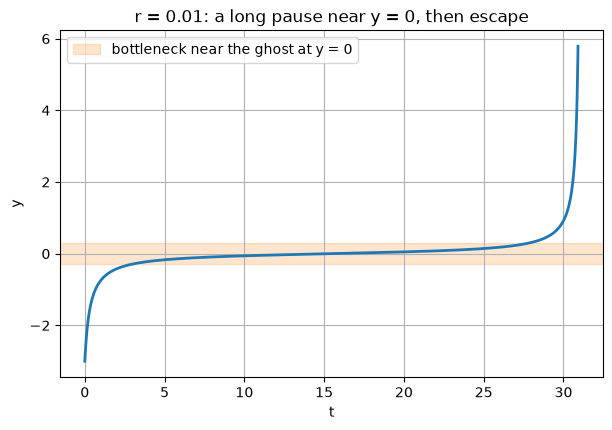

In [7]:
t, Y = rk4(lambda t, y: 0.01 + y**2, 0, -3.0, 0.01, 3100)   # stop at t = 31, just before blow-up
mask = np.abs(Y) < 6
plt.plot(t[mask], Y[mask], lw=2)
plt.axhspan(-0.3, 0.3, color="C1", alpha=0.2, label="bottleneck near the ghost at y = 0")
plt.xlabel("t"); plt.ylabel("y"); plt.title("r = 0.01: a long pause near y = 0, then escape")
plt.legend();

## 5. Transcritical bifurcation

**Normal form:** $\quad y' = ry - y^2 = y(r - y).$

* **Equilibria:** $y^* = 0$ and $y^* = r$. They exist for **all** $r$ and cross at $r = 0$.
* **Stability:** $f'(y) = r - 2y$.
  * at $y^* = 0$: $f' = r$, stable for $r < 0$, unstable for $r > 0$
  * at $y^* = r$: $f' = r - 2r = -r$, unstable for $r < 0$, stable for $r > 0$

At $r = 0$ the two equilibria pass through each other and **exchange stability**.

### Worked example 5.1

Take $r = 2$. The equilibria are $0$ (since $f'(0) = 2$, unstable) and $2$ (since $f'(2) = -2$, stable). This is the logistic equation: a small population starting at $y_0 = 0.1$ grows to the carrying capacity $2$. If instead $r = -1$, the only stable state is $y^* = 0$: the population dies out.

**Typical setting:** whenever $y = 0$ is an equilibrium for every $r$ (zero population, zero laser output, zero infection), a transcritical bifurcation marks the **threshold** where the non-zero state takes over. In epidemics this is the condition $R_0 = 1$.

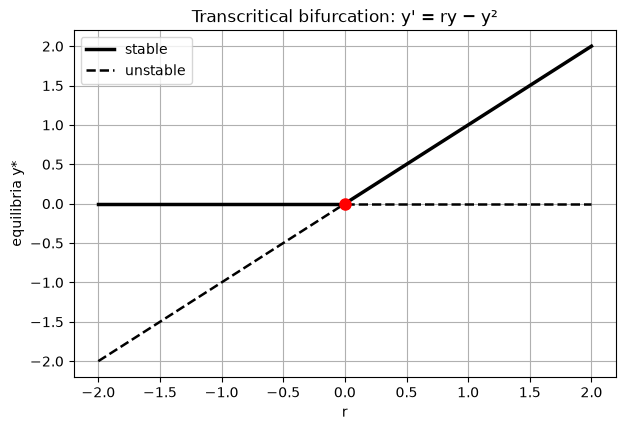

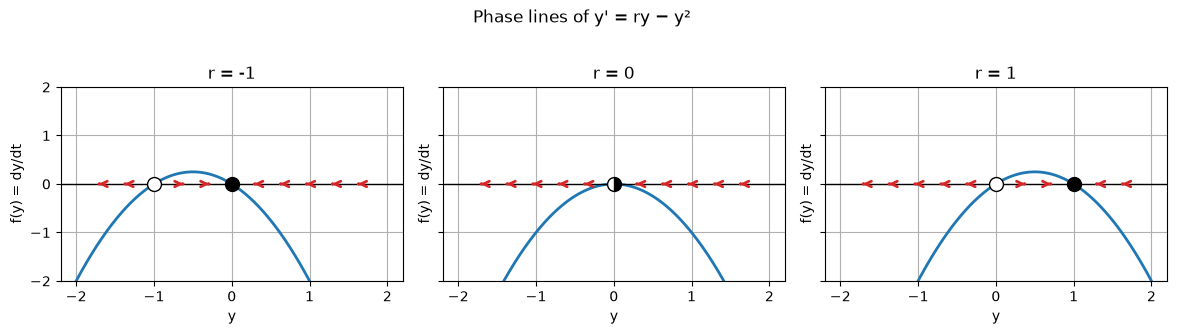

In [8]:
fig, ax = plt.subplots()
rn, rp = np.linspace(-2, 0, 100), np.linspace(0, 2, 100)
branch(ax, rn, 0 * rn, True, label="stable"); branch(ax, rp, 0 * rp, False, label="unstable")
branch(ax, rn, rn, False); branch(ax, rp, rp, True)
ax.plot(0, 0, "ro", ms=8)
ax.set_xlabel("r"); ax.set_ylabel("equilibria y*")
ax.set_title("Transcritical bifurcation: y' = ry − y²"); ax.legend();

phase_lines_row(lambda y, r: r * y - y**2, [-1, 0, 1], (-2, 2), "Phase lines of y' = ry − y²")

## 6. Pitchfork bifurcations

These occur in systems with a **symmetry** $y \to -y$, meaning $f(-y) = -f(y)$, so equilibria appear in symmetric pairs.

### 6.1 Supercritical pitchfork

**Normal form:** $\quad y' = ry - y^3.$

* **Equilibria:** $y(r - y^2) = 0$, so $y^* = 0$ always, and $y^* = \pm\sqrt{r}$ when $r > 0$.
* **Stability:** $f'(y) = r - 3y^2$.
  * at $y^* = 0$: $f' = r$, stable for $r < 0$, unstable for $r > 0$
  * at $y^* = \pm\sqrt{r}$: $f' = r - 3r = -2r < 0$, **stable**

As $r$ passes 0, the single stable state at $0$ becomes unstable and two new stable states branch off **smoothly**. The system must "choose" one: this is **symmetry breaking**, as in a buckling beam, which bends either left or right.

**Worked example 6.1.** At $r = 4$ the equilibria are $0$ (since $f'(0) = 4$, unstable) and $\pm 2$ (since $f'(\pm 2) = 4 - 12 = -8$, stable). Starting at $y_0 = 0.01$ the solution goes to $+2$; starting at $y_0 = -0.01$ it goes to $-2$.

### 6.2 Subcritical pitchfork

**Normal form:** $\quad y' = ry + y^3.$

* **Equilibria:** $y^* = 0$ always, and $y^* = \pm\sqrt{-r}$ when $r < 0$.
* **Stability:** $f'(y) = r + 3y^2$.
  * at $y^* = 0$: $f' = r$, stable for $r < 0$, unstable for $r > 0$
  * at $y^* = \pm\sqrt{-r}$: $f' = r - 3r = -2r > 0$ for $r < 0$, **unstable**

Now the side branches are unstable and exist *before* the bifurcation. For $r < 0$, the origin is stable only for perturbations smaller than $\sqrt{-r}$. For $r > 0$ there is nothing nearby to go to and solutions **blow up**. The change is sudden and dangerous, with no gradual warning in the equilibrium value itself.

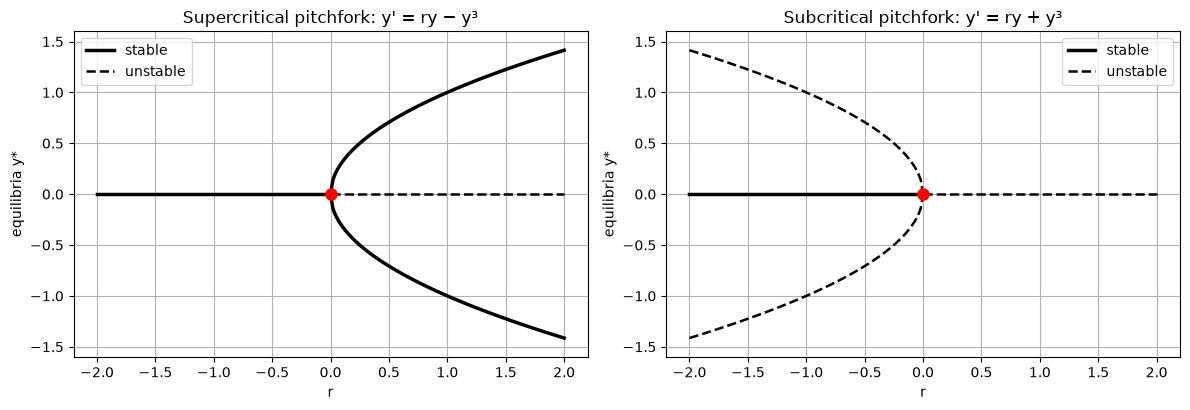

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

ax = axes[0]
rn, rp = np.linspace(-2, 0, 100), np.linspace(0, 2, 100)
branch(ax, rn, 0 * rn, True, label="stable"); branch(ax, rp, 0 * rp, False, label="unstable")
branch(ax, rp, np.sqrt(rp), True); branch(ax, rp, -np.sqrt(rp), True)
ax.plot(0, 0, "ro", ms=8)
ax.set_title("Supercritical pitchfork: y' = ry − y³")

ax = axes[1]
branch(ax, rn, 0 * rn, True, label="stable"); branch(ax, rp, 0 * rp, False, label="unstable")
branch(ax, rn, np.sqrt(-rn), False); branch(ax, rn, -np.sqrt(-rn), False)
ax.plot(0, 0, "ro", ms=8)
ax.set_title("Subcritical pitchfork: y' = ry + y³")

for ax in axes:
    ax.set_xlabel("r"); ax.set_ylabel("equilibria y*"); ax.set_ylim(-1.6, 1.6); ax.legend()
plt.tight_layout()

final values: [-2. -2.  2.  2.  2. -2.]


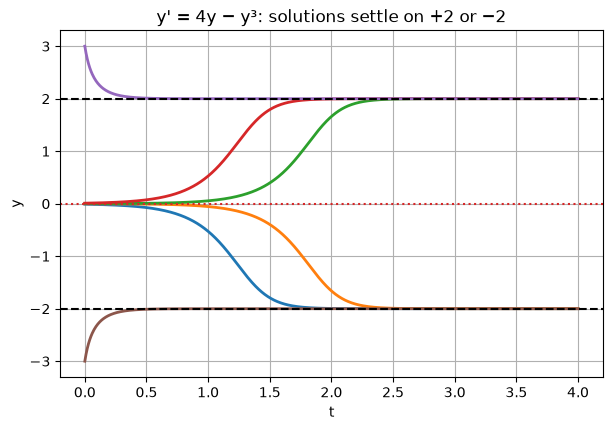

In [10]:
# Symmetry breaking at r = 4: tiny differences in the initial condition decide the final state
t, Y = rk4(lambda t, y: 4 * y - y**3, 0, np.array([-0.01, -0.001, 0.001, 0.01, 3.0, -3.0]), 0.005, 800)
plt.plot(t, Y, lw=2)
for ys in [-2, 2]:
    plt.axhline(ys, color="k", ls="--")
plt.axhline(0, color="C3", ls=":")
plt.xlabel("t"); plt.ylabel("y"); plt.title("y' = 4y − y³: solutions settle on +2 or −2")
print("final values:", np.round(Y[-1], 6))

## 7. Hysteresis

Real systems usually have higher-order terms that stop the blow-up of a subcritical pitchfork. A standard example is

$$y' = r + y - y^3.$$

For a range of $r$ there are **three** equilibria (two stable, one unstable); outside it there is only one. The edges of that range are two **saddle-node** bifurcations.

### Worked example 7.1: locating the bifurcation points

Solve $f = 0$ and $f_y = 0$ simultaneously:

$$f_y = 1 - 3y^2 = 0 \;\Rightarrow\; y^* = \pm\frac{1}{\sqrt{3}}, \qquad r_c = y^3 - y = \mp\frac{1}{\sqrt{3}}\left(1 - \frac{1}{3}\right) = \mp\frac{2}{3\sqrt{3}} \approx \mp 0.3849.$$

So for $-0.3849 < r < 0.3849$ the system is **bistable**.

**Hysteresis.** Increase $r$ slowly from $-1$. The system follows the lower stable branch until that branch disappears at $r \approx +0.385$, then **jumps** to the upper branch. Now decrease $r$: the system stays on the upper branch until $r \approx -0.385$ and only then jumps back down. The state depends on the *history* of $r$, not just its current value. Examples include magnets, switches in cells and lake eutrophication.

theory: saddle-nodes at r = ±0.3849
simulation: jumps up near r = 0.415, down near r = -0.415


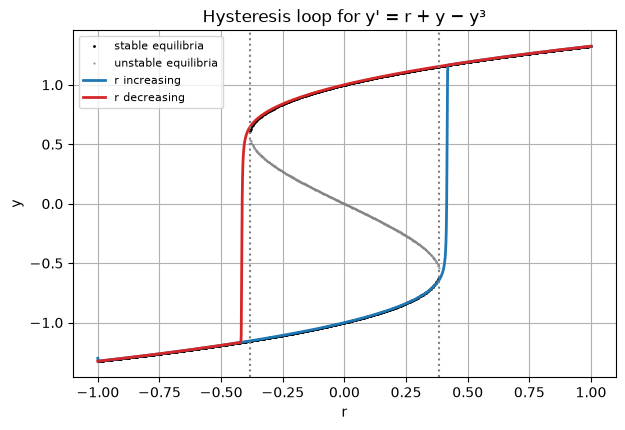

In [11]:
# Equilibria for each r from the cubic  -y^3 + y + r = 0
rs = np.linspace(-1, 1, 801)
stab_r, stab_y, unst_r, unst_y = [], [], [], []
for r in rs:
    for y in np.roots([-1, 0, 1, r]):
        if abs(y.imag) < 1e-9:
            y = y.real
            (stab_r if 1 - 3 * y**2 < 0 else unst_r).append(r)
            (stab_y if 1 - 3 * y**2 < 0 else unst_y).append(y)

# Slow sweep of r up and then down while integrating y' = r(t) + y - y^3
T = 2000.0
r_of_t = lambda t: -1 + 2 * t / (T / 2) if t < T / 2 else 1 - 2 * (t - T / 2) / (T / 2)
t, Y = rk4(lambda t, y: r_of_t(t) + y - y**3, 0, -1.3, 0.05, int(T / 0.05))
r_path = np.array([r_of_t(ti) for ti in t])
up = t < T / 2

plt.plot(stab_r, stab_y, "k.", ms=2, label="stable equilibria")
plt.plot(unst_r, unst_y, ".", color="gray", ms=1, label="unstable equilibria")
plt.plot(r_path[up], Y[up], "C0", lw=2, label="r increasing")
plt.plot(r_path[~up], Y[~up], "C3", lw=2, label="r decreasing")
rc = 2 / (3 * np.sqrt(3))
for x in [-rc, rc]:
    plt.axvline(x, color="gray", ls=":")
plt.xlabel("r"); plt.ylabel("y"); plt.title("Hysteresis loop for y' = r + y − y³")
plt.legend(fontsize=8)

jump_up = r_path[up][np.argmax(Y[up] > 0)]
jump_down = r_path[~up][np.argmax(Y[~up] < 0)]
print(f"theory: saddle-nodes at r = ±{rc:.4f}")
print(f"simulation: jumps up near r = {jump_up:.3f}, down near r = {jump_down:.3f}")

In the simulation the jumps happen a little *after* $\pm 0.385$, because $r$ is changing at a finite rate and the solution needs time to leave the bottleneck. This delay is the "ghost" effect from Section 4.

## 8. Application: harvesting and sudden collapse

A fish population grows logistically and is harvested at a constant rate $H$ (fish per year):

$$\frac{dP}{dt} = rP\left(1 - \frac{P}{K}\right) - H.$$

**Equilibria:** $rP - \dfrac{r}{K}P^2 - H = 0$, so

$$P^* = \frac{K}{2}\left(1 \pm \sqrt{1 - \frac{4H}{rK}}\right).$$

They exist only when $H \le \dfrac{rK}{4}$. The larger root is stable (a healthy population); the smaller root is unstable (a threshold below which the population crashes). At the **maximum sustainable yield** $H_c = rK/4$ they merge in a **saddle-node** bifurcation.

### Worked example 8.1

Take $r = 0.5$ per year and $K = 1000$, so $H_c = 0.5 \times 1000 / 4 = 125$ fish per year.

* **$H = 100$:** $P^2 - 1000P + 200\,000 = 0$, so $P^* = 500 \pm \sqrt{50\,000} = 500 \pm 223.6$, giving
  $P^* = 723.6$ (stable) and $P^* = 276.4$ (unstable).
* **$H = 120$:** $P^* = 500 \pm \sqrt{10\,000} = 600$ (stable) and $400$ (unstable). The safety margin has shrunk.
* **$H = 125$:** $P^* = 500$ (semi-stable). This is the tipping point.
* **$H = 130$:** no equilibria. Every population eventually collapses to zero.

**The danger:** as $H$ increases towards 125, the stable population falls only gradually, from 1000 to about 724, then 600, then 500. Nothing in the equilibrium value warns of the collapse. Just past $H_c$ the fishery is gone. Because of the bottleneck, the decline is slow at first, which makes it easy to miss.

    H  stable P*  unstable P*
    0     1000.0          0.0
   50      887.3        112.7
  100      723.6        276.4
  120      600.0        400.0
  125      500.0        500.0


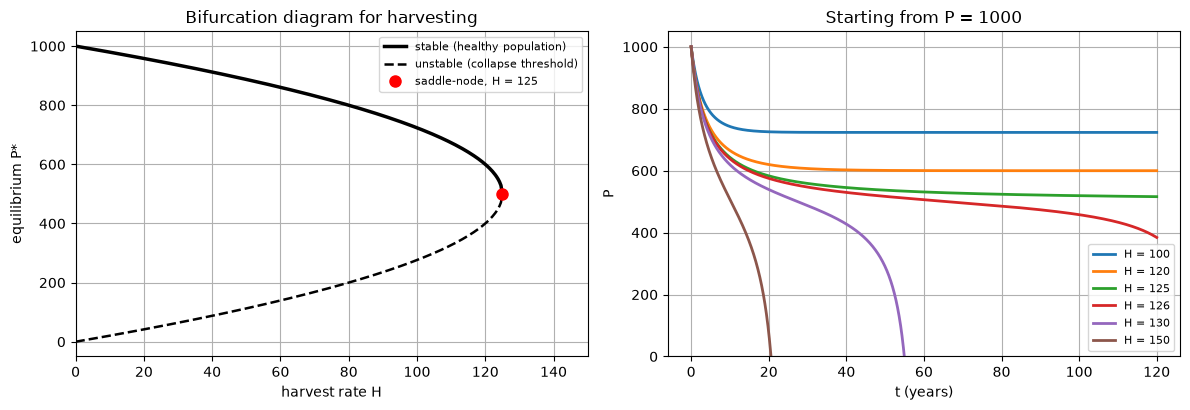

In [12]:
r, K = 0.5, 1000.0
Hc = r * K / 4
H = np.linspace(0, Hc, 300)
disc = np.sqrt(1 - 4 * H / (r * K))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
branch(ax, H, K / 2 * (1 + disc), True, label="stable (healthy population)")
branch(ax, H, K / 2 * (1 - disc), False, label="unstable (collapse threshold)")
ax.plot(Hc, K / 2, "ro", ms=8, label=f"saddle-node, H = {Hc:.0f}")
ax.set_xlim(0, 150); ax.set_xlabel("harvest rate H"); ax.set_ylabel("equilibrium P*")
ax.set_title("Bifurcation diagram for harvesting"); ax.legend(fontsize=8)

ax = axes[1]
for Hval in [100, 120, 125, 126, 130, 150]:
    rhs = lambda t, P: r * P * (1 - P / K) - Hval if P > 0 else 0.0   # freeze once extinct
    t, P = rk4(rhs, 0, 1000.0, 0.05, 2400)
    P = np.where(P <= 0, np.nan, P)           # stop plotting once the population is gone
    ax.plot(t, P, lw=2, label=f"H = {Hval}")
ax.set_xlabel("t (years)"); ax.set_ylabel("P"); ax.set_ylim(0, 1050)
ax.set_title("Starting from P = 1000"); ax.legend(fontsize=8)
plt.tight_layout()

print(f"{'H':>5} {'stable P*':>10} {'unstable P*':>12}")
for Hval in [0, 50, 100, 120, 125]:
    d = np.sqrt(max(0.0, 1 - 4 * Hval / (r * K)))
    print(f"{Hval:5d} {K/2*(1+d):10.1f} {K/2*(1-d):12.1f}")

In [13]:
# How long until collapse just beyond the tipping point?  (bottleneck time ~ 1/sqrt(H - Hc))
def collapse_time(Hval, h=0.01):
    P, t = 1000.0, 0.0
    g = lambda P: r * P * (1 - P / K) - Hval
    while P > 0:
        k1 = g(P); k2 = g(P + h/2*k1); k3 = g(P + h/2*k2); k4 = g(P + h*k3)
        P += h / 6 * (k1 + 2*k2 + 2*k3 + k4); t += h
    return t

print(f"{'H':>6} {'years to collapse':>18}")
for Hval in [126, 130, 140, 150, 200]:
    print(f"{Hval:6d} {collapse_time(Hval):18.1f}")

     H  years to collapse
   126              132.5
   130               54.9
   140               28.6
   150               20.6
   200                9.4


Overshooting the maximum sustainable yield by just 1 fish per year (126 instead of 125) still destroys the population; it only takes longer.

## 9. Computing bifurcation diagrams numerically

For realistic models, $f(y, r) = 0$ usually cannot be solved by hand. There are three standard numerical approaches.

### 9.1 Root finding over a grid of $r$

For each $r$, find all roots of $f(\cdot, r)$ and classify each one by the sign of $f_y$. We did this in Section 7 with `np.roots`, because $f$ was a polynomial. For a general $f$, scan for sign changes, then refine each root with Newton's method:

$$y_{k+1} = y_k - \frac{f(y_k, r)}{f_y(y_k, r)}.$$

### 9.2 Brute-force simulation

Integrate from many initial conditions for a long time and plot the final values. This finds only the **stable** equilibria, but it needs nothing except a simulator, and it also works when equilibria are not the whole story.

### 9.3 Solving directly for the bifurcation point

Treat $(y, r)$ as two unknowns and solve the $2 \times 2$ system $f = 0$, $f_y = 0$ with Newton's method. Below, all three are applied to examples from these notes.

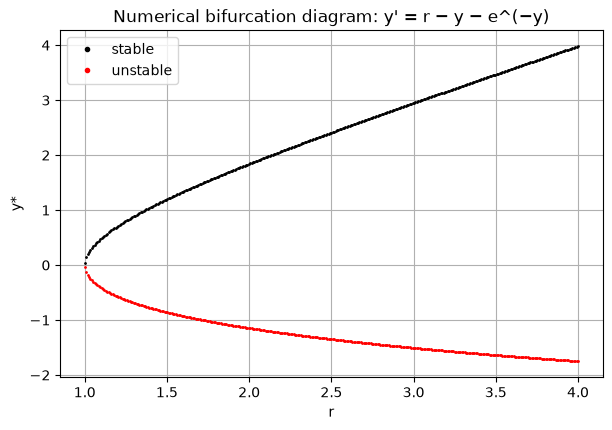

In [14]:
# 9.1  Grid scan + Newton for a non-polynomial model: y' = r - y - exp(-y)
F  = lambda y, r: r - y - np.exp(-y)
Fy = lambda y, r: -1 + np.exp(-y)

def equilibria(F, Fy, r, ygrid):
    vals = F(ygrid, r)
    roots = []
    for i in np.where(np.sign(vals[:-1]) * np.sign(vals[1:]) < 0)[0]:
        y = 0.5 * (ygrid[i] + ygrid[i + 1])
        for _ in range(30):                       # Newton refinement
            y -= F(y, r) / Fy(y, r)
        roots.append(y)
    return roots

ygrid = np.linspace(-4, 6, 4001)
for r in np.linspace(0.6, 4, 400):
    for y in equilibria(F, Fy, r, ygrid):
        plt.plot(r, y, "k." if Fy(y, r) < 0 else "r.", ms=2)
plt.plot([], [], "k.", label="stable"); plt.plot([], [], "r.", label="unstable")
plt.xlabel("r"); plt.ylabel("y*"); plt.title("Numerical bifurcation diagram: y' = r − y − e^(−y)")
plt.legend();

The diagram shows a saddle-node bifurcation at $r = 1$. *Check by hand:* $F_y = 0$ gives $e^{-y} = 1$, so $y^* = 0$; then $F = 0$ gives $r_c = 0 + e^{0} = 1$. ✓

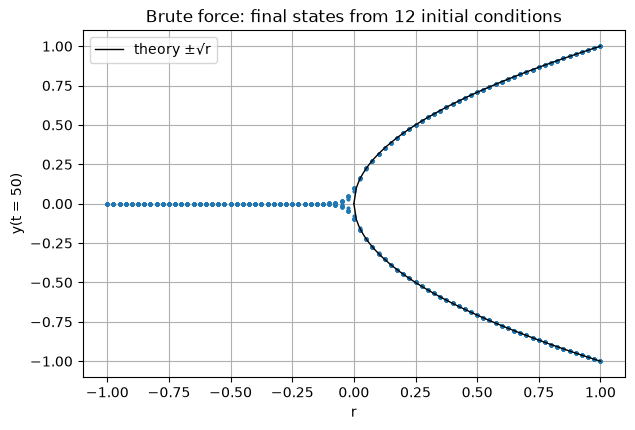

In [15]:
# 9.2  Brute force for the supercritical pitchfork y' = ry - y^3
rs = np.linspace(-1, 1, 81)
y0s = np.linspace(-1.5, 1.5, 12)
for r in rs:
    _, Y = rk4(lambda t, y: r * y - y**3, 0, y0s, 0.02, 2500)   # integrate to t = 50
    plt.plot(np.full(len(y0s), r), Y[-1], "C0.", ms=4)
rp = np.linspace(0, 1, 100)
plt.plot(rp, np.sqrt(rp), "k-", lw=1, label="theory ±√r")
plt.plot(rp, -np.sqrt(rp), "k-", lw=1)
plt.xlabel("r"); plt.ylabel("y(t = 50)"); plt.title("Brute force: final states from 12 initial conditions")
plt.legend();

Only the stable branches appear, and the unstable $y = 0$ for $r > 0$ is invisible. Notice the spread near $r = 0$. There $f'(0) \approx 0$, so the approach to equilibrium is extremely slow (for $r = 0$, $y' = -y^3$ decays only like $1/\sqrt{2t}$). This **critical slowing down** is another warning sign that a bifurcation is near.

In [16]:
# 9.3  Newton's method on the 2x2 system  f = 0, f_y = 0  for the hysteresis model y' = r + y - y^3
def bifurcation_point(y, r, steps=8):
    print(f"{'k':>2} {'y':>12} {'r':>12} {'|f|+|f_y|':>12}")
    for k in range(steps):
        Fv = np.array([r + y - y**3, 1 - 3 * y**2])
        print(f"{k:2d} {y:12.8f} {r:12.8f} {np.abs(Fv).sum():12.2e}")
        J = np.array([[1 - 3 * y**2, 1.0],      # d/dy, d/dr of f
                      [-6 * y,       0.0]])     # d/dy, d/dr of f_y
        dy, dr = np.linalg.solve(J, -Fv)
        y, r = y + dy, r + dr
    return y, r

y_c, r_c = bifurcation_point(0.8, 0.0)
print(f"\nNewton:  y* = {y_c:.8f},  r_c = {r_c:.8f}")
print(f"Exact:   y* = {1/np.sqrt(3):.8f},  r_c = {-2/(3*np.sqrt(3)):.8f}")

 k            y            r    |f|+|f_y|
 0   0.80000000   0.00000000     1.21e+00
 1   0.60833333  -0.46433333     1.91e-01
 2   0.57813927  -0.38653539     4.37e-03
 3   0.57735081  -0.38490126     2.94e-06
 4   0.57735027  -0.38490018     1.37e-12
 5   0.57735027  -0.38490018     2.78e-17
 6   0.57735027  -0.38490018     2.78e-17
 7   0.57735027  -0.38490018     2.78e-17

Newton:  y* = 0.57735027,  r_c = -0.38490018
Exact:   y* = 0.57735027,  r_c = -0.38490018


Newton converges quadratically: the number of correct digits roughly doubles each iteration. This is how software such as AUTO, MatCont or Julia's BifurcationKit.jl locates bifurcation points, combined with **continuation**, which follows a branch of equilibria step by step in $r$.

## 10. Summary

| Type | Normal form | Equilibria | Bifurcation diagram | Meaning |
|---|---|---|---|---|
| Saddle-node | $y' = r + y^2$ | $\pm\sqrt{-r}$ for $r<0$ | a parabola that ends at the bifurcation point | equilibria created or destroyed; tipping points |
| Transcritical | $y' = ry - y^2$ | $0$ and $r$ | two crossing lines | exchange of stability; thresholds |
| Supercritical pitchfork | $y' = ry - y^3$ | $0$; $\pm\sqrt{r}$ for $r>0$ | stable branches open after $r_c$ | smooth symmetry breaking |
| Subcritical pitchfork | $y' = ry + y^3$ | $0$; $\pm\sqrt{-r}$ for $r<0$ | unstable branches before $r_c$ | sudden jump or blow-up |

**Recipe for analysing $y' = f(y, r)$**
1. Find the equilibria: solve $f(y, r) = 0$.
2. Classify each one by the sign of $f_y(y^*, r)$.
3. Find the bifurcation points: solve $f = 0$ and $f_y = 0$ together.
4. Draw the bifurcation diagram (solid = stable, dashed = unstable) and phase lines on either side of each $r_c$.
5. Confirm with simulations.

**Warning signs near a bifurcation:** slow recovery from perturbations (critical slowing down), long pauses (bottlenecks), and a shrinking distance between the stable and unstable equilibria.

## 11. Exercises

1. $y' = r - y^2$. Find the equilibria, their stability and the bifurcation type.
2. $y' = ry + y^2$. Find the equilibria and their stability, and identify the bifurcation.
3. $y' = ry - \sin y$. Show that $y^* = 0$ changes stability at $r = 1$. Use $\sin y \approx y - y^3/6$ to decide whether the pitchfork is super- or subcritical.
4. In the harvesting model with $r = 0.5$ and $K = 1000$, find the equilibria for $H = 120$. What is the smallest population that recovers?
5. Find the bifurcation point of $y' = r + y - \ln(1 + y)$ for $y > -1$.

**Answers**

1. $y^* = \pm\sqrt{r}$ for $r > 0$, with $f' = -2y$: $+\sqrt{r}$ is stable and $-\sqrt{r}$ unstable. A saddle-node at $r = 0$, with the branches opening to the right.
2. $y^* = 0$ and $y^* = -r$, with $f' = r + 2y$: $f'(0) = r$ and $f'(-r) = -r$. A transcritical bifurcation at $r = 0$: $y^* = 0$ is stable for $r < 0$ and $y^* = -r$ is stable for $r > 0$.
3. $f'(0) = r - \cos 0 = r - 1$, which changes sign at $r = 1$. Near $0$, $f \approx (r - 1)y + y^3/6$. The cubic term has a **plus** sign, so the pitchfork is **subcritical**.
4. $P^* = 600$ (stable) and $P^* = 400$ (unstable). Any population above 400 recovers to 600.
5. $f_y = 1 - \dfrac{1}{1+y} = 0 \Rightarrow y^* = 0$, and then $f = r + 0 - 0 = 0 \Rightarrow r_c = 0$. For $r < 0$ there are two equilibria (one on each side of 0) and for $r > 0$ none: a saddle-node. Check it numerically below.

In [17]:
# Exercise 5 check: count equilibria of y' = r + y - ln(1+y) for a few r
F5  = lambda y, r: r + y - np.log1p(y)
F5y = lambda y, r: 1 - 1 / (1 + y)
ygrid = np.linspace(-0.999, 5, 20001)
for r in [-0.5, -0.1, 0.1]:
    eq = equilibria(F5, F5y, r, ygrid)
    desc = ", ".join(f"{y:.4f} ({'stable' if F5y(y, r) < 0 else 'unstable'})" for y in eq) or "none"
    print(f"r = {r:5.2f}: equilibria {desc}")

r = -0.50: equilibria -0.6983 (stable), 1.3577 (unstable)
r = -0.10: equilibria -0.3832 (stable), 0.5162 (unstable)
r =  0.10: equilibria none
